# Matplotlib + Seaborn с нуля: курс на 1 час

Запускай ноутбук из папки `ML` — пути к данным относительные (`02/…`, `03/…`).

| Время | Что делаешь |
|---|---|
| 0:00–0:03 | Подготовка (одна ячейка) |
| 0:03–0:23 | **Matplotlib**: устройство, `plot/scatter/bar/hist`, оформление, `subplots`, даты |
| 0:23–0:30 | Графики из **Pandas** (`.plot`) |
| 0:30–0:40 | **Seaborn**: `scatterplot`, `histplot`, `countplot/boxplot`, `heatmap` |
| 0:40–0:55 | **Тесты**: 12 задач с автопроверкой `[OK]` / `[X]` |
| 0:55–1:00 | Журнал ошибок |

**Как учиться:** правило → запусти пример → поменяй число/цвет и запусти снова. Тесты решай **до** того, как откроешь «Эталон» внизу.
Если не успеваешь — в теории читай только жирное и таблицы, в тестах главное **ЛР5·1–8**.

## 0. Подготовка (запусти один раз)

Ячейка ниже подключает библиотеки, загружает данные из лаб и определяет функции `ok(...)`, `check(...)`, `note(...)`, которые проверяют твои решения.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
import matplotlib.colors as mcolors, seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120); pd.set_option("display.max_columns", 12)

# --- данные из твоих лаб ---
rec = pd.read_csv("02/recipes_sample.csv", parse_dates=["submitted"])      # 30 000 рецептов
rev = pd.read_csv("02/reviews_sample.csv", index_col=0, parse_dates=["date"])  # 126 696 отзывов
ratings = np.load("03/average_ratings.npy")                                 # (3, 1095): средний рейтинг 3 рецептов по дням
visitors = np.load("03/visitors.npy")                                       # (100,): посетители сайта по дням
names = ["waffle iron french toast", "zwetschgenkuchen bavarian plum cake", "lime tea"]
rec["kind"] = pd.cut(rec["minutes"], bins=[0, 5, 50, np.inf], labels=["короткие", "средние", "длинные"], right=False)
print(rec.shape, rev.shape, ratings.shape, visitors.shape)

# --- проверялки ---
ERRORS, NOTES = [], []

def ok(name, fn):
    """Проверка условия. Печатает [OK] или [X]."""
    try: good = bool(fn())
    except Exception as e: good = False
    print(("[OK] " if good else "[X]  ") + name)
    if not good: ERRORS.append(name)

def check(name, got_fn, exp):
    """Сравнить результат с ожидаемым."""
    try:
        got = got_fn()
        good = bool(got == exp) if isinstance(exp, (str, bool)) else bool(np.allclose(np.asarray(got, float), np.asarray(exp, float)))
    except Exception as e: got, good = f"{type(e).__name__}: {e}", False
    print(("[OK] " if good else "[X]  ") + name)
    if not good: ERRORS.append(name); print("     получил:", repr(got)[:120], "| ожидалось:", repr(exp)[:120])

def note(text):
    """Журнал ошибок: запиши, что перепутал."""
    NOTES.append(text); print("записано:", text)

def leg(ax):   # тексты легенды
    lg = ax.get_legend()
    return [t.get_text() for t in lg.get_texts()] if lg else []
def colors(ax):   # цвета линий в hex
    return [mcolors.to_hex(l.get_color()) for l in ax.lines]
def sup(fig):     # общий заголовок фигуры
    return fig._suptitle.get_text() if fig._suptitle else ""

(30000, 9) (126696, 5) (3, 1095) (100,)


# 1. Matplotlib (20 мин)

## 1.1 Как устроен график — 5 мин

Представь **холст с картинами**:

| Объект | Что это | Аналогия |
|---|---|---|
| `Figure` (`fig`) | весь рисунок целиком | холст / окно |
| `Axes` (`ax`) | **один график** с осями, сеткой, линиями | одна картина на холсте |
| `Axis` | ось X или Y (засечки и подписи) | линейка |
| `Artist` | всё, что нарисовано: линия, точка, текст | мазок кисти |

⚠️ `Axes` ≠ `Axis`. `ax` — это график, а `ax.xaxis` — его горизонтальная ось.

**Два способа рисовать.** Всегда используй второй.
1. `plt.plot(x, y)` — «быстрый», рисует на «текущем» графике. Для настройки неудобен.
2. **`fig, ax = plt.subplots()` → `ax.plot(x, y)`** — явный. Тут точно знаешь, на каком графике что рисуешь.

Шаблон любого графика:
```python
fig, ax = plt.subplots(figsize=(8, 4))   # 1. создаём холст и график
ax.plot(x, y, label="...")               # 2. рисуем
ax.set(title="...", xlabel="...", ylabel="...")   # 3. подписываем
ax.legend()                              # 4. легенда (по label=)
plt.show()                               # 5. показать (в ноутбуке можно без него)
```

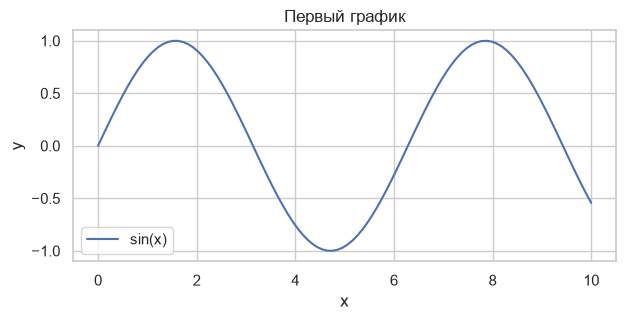

Figure Axes


In [43]:
x = np.linspace(0, 10, 100)           # 100 точек от 0 до 10 (конец включён)

fig, ax = plt.subplots(figsize=(7, 3))   # figsize = (ширина, высота) в дюймах
ax.plot(x, np.sin(x), label="sin(x)")
ax.set_title("Первый график")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend()
plt.show()
print(type(fig).__name__, type(ax).__name__)

**Попробуй:** поменяй `figsize` на `(3, 3)`, потом на `(12, 2)`. Увидишь, что меняется форма холста.
Сохранить в файл: `fig.savefig("pic.png", dpi=150, bbox_inches="tight")` (`dpi` — чёткость, `bbox_inches="tight"` — обрезать белые поля).

## 1.2 Линия — `ax.plot` — 5 мин

`ax.plot(x, y)` соединяет точки **по порядку** ломаной. Если дать один массив `ax.plot(y)` — по X пойдут номера `0, 1, 2…`.

| Параметр | Что делает | Значения |
|---|---|---|
| `label` | имя для легенды | `"sin"` |
| `color` / `c` | цвет | `"red"`, `"#ff8800"`, `"tab:blue"`, `"C0"`, `"0.5"` (серый) |
| `linestyle` / `ls` | стиль линии | `"-"` `"--"` `":"` `"-."` `""` (нет) |
| `linewidth` / `lw` | толщина | `1`, `2.5` |
| `marker` | маркер точек | `"o"` `"s"` `"^"` `"x"` `"."` |
| `alpha` | прозрачность | от `0` (невидимо) до `1` |

Сокращённая запись: `ax.plot(x, y, "r--o")` = красный, пунктир, кружки.
Если рисуешь несколько линий подряд на одном `ax`, цвета меняются сами (`C0, C1, C2…`).

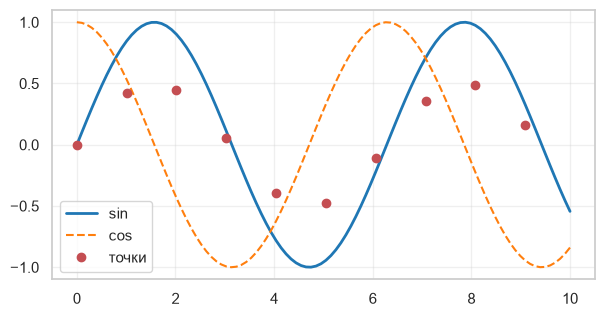

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(x, np.sin(x), label="sin", color="tab:blue", lw=2)
ax.plot(x, np.cos(x), label="cos", color="tab:orange", ls="--")
ax.plot(x[::10], np.sin(x[::10]) / 2, "ro", label="точки")      # r=red, o=кружки, без линии
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 1.3 Точки — `ax.scatter` — 3 мин

`ax.scatter(x, y)` рисует **отдельные точки** (диаграмма рассеяния) — для связи двух признаков.
- `s=` — размер, `c=` — цвет (или массив чисел → раскраска по значению, нужен `cmap=`), `alpha=` — прозрачность (когда точек много — обязательно!).
- `plt.colorbar(sc, ax=ax)` — шкала цвета.

Чем `plot` отличается от `scatter`: `plot` соединяет линией и быстрее; `scatter` умеет задавать **каждой точке свой размер/цвет**.

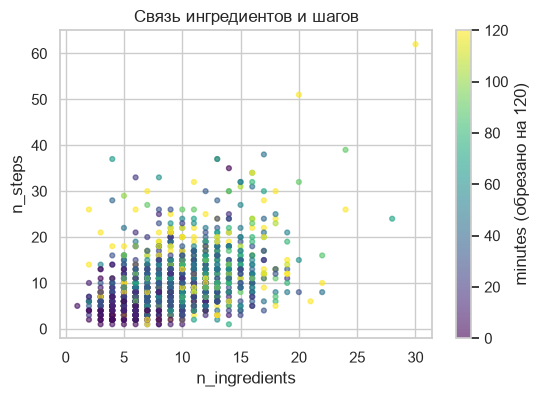

In [4]:
s = rec.dropna(subset=["n_steps", "n_ingredients"]).sample(1500, random_state=0)
fig, ax = plt.subplots(figsize=(6, 4))
sc = ax.scatter(s["n_ingredients"], s["n_steps"], c=s["minutes"].clip(upper=120), cmap="viridis", s=12, alpha=0.6)
plt.colorbar(sc, ax=ax, label="minutes (обрезано на 120)")
ax.set(xlabel="n_ingredients", ylabel="n_steps", title="Связь ингредиентов и шагов")
plt.show()

## 1.4 Столбцы — `bar` / `barh` — 4 мин

`ax.bar(x, height)` — вертикальные, `ax.barh(y, width)` — горизонтальные (удобно при длинных названиях).
Для сравнения **категорий** (сколько рецептов у каждого автора, средний рейтинг по группам).
- `x` может быть строками — ось сама станет категориальной.
- Ширина: `width=0.6`; цвет: `color=`, граница `edgecolor=`; погрешность `yerr=`.
- Подписи значений на столбцах: `ax.bar_label(bars)`.
- **Сгруппированные** столбцы: сдвигай X: `x - w/2` и `x + w/2`.
- **Стопкой**: второй вызов с `bottom=`.

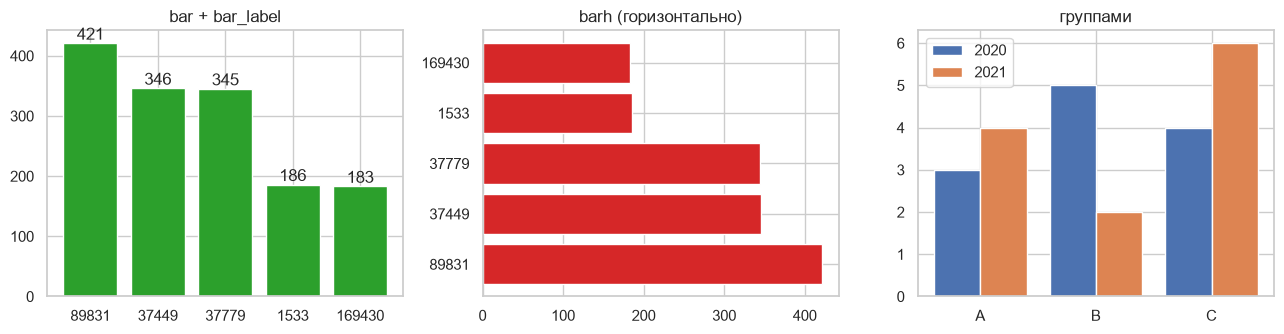

In [5]:
top = rec["contributor_id"].value_counts().head(5)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

bars = axes[0].bar(top.index.astype(str), top.values, color="tab:green")
axes[0].bar_label(bars); axes[0].set_title("bar + bar_label")

axes[1].barh(top.index.astype(str), top.values, color="tab:red")
axes[1].set_title("barh (горизонтально)")

cats = np.arange(3); w = 0.4
axes[2].bar(cats - w/2, [3, 5, 4], w, label="2020")     # сгруппированные: сдвиг на пол-ширины
axes[2].bar(cats + w/2, [4, 2, 6], w, label="2021")
axes[2].set_xticks(cats, ["A", "B", "C"]); axes[2].legend(); axes[2].set_title("группами")
plt.tight_layout(); plt.show()

## 1.5 Гистограмма — `hist` — 4 мин

`ax.hist(data, bins=...)` разбивает значения на **корзины (bins)** и показывает, сколько значений попало в каждую. Это **распределение одного числового признака**.
- `bins=20` — число корзин (или список границ). Мало корзин — грубо, много — шумно.
- `range=(0, 100)` — какой диапазон учитывать. `density=True` — площадь = 1 (доли, а не штуки).
- `edgecolor="white"` — границы столбцов (так лучше видно).
- Возвращает `(counts, bin_edges, patches)`.

📌 **bar vs hist:** `bar` — *категории*, считаешь заранее. `hist` — *сырые числа*, он сам считает корзины.

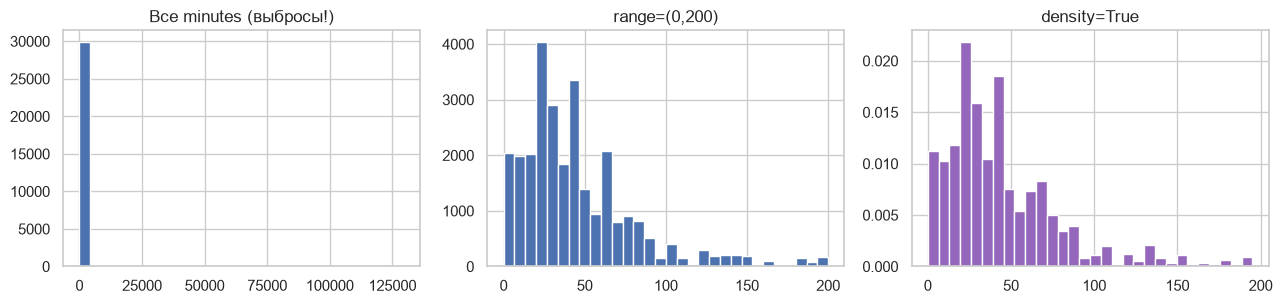

[6071 8792 5707 3767 1686] [  0.  20.  40.  60.  80. 100.]


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
m = rec["minutes"]
axes[0].hist(m, bins=30);                                axes[0].set_title("Все minutes (выбросы!)")
axes[1].hist(m, bins=30, range=(0, 200), edgecolor="white"); axes[1].set_title("range=(0,200)")
axes[2].hist(m[m < 200], bins=30, density=True, color="tab:purple"); axes[2].set_title("density=True")
plt.tight_layout(); plt.show()
counts, edges = np.histogram(m, bins=5, range=(0, 100))
print(counts, edges)          # то же, что считает hist, но без картинки

## 1.6 Остальные типы — 5 мин

| Что показать | Метод | Заметка |
|---|---|---|
| разброс, медиану, выбросы | `ax.boxplot([a, b, c])` | ящик = от 25% до 75%, линия = медиана, «усы», точки = выбросы |
| доли целого | `ax.pie(values, labels=…, autopct="%.0f%%")` | не больше 5–6 долей |
| область между линиями | `ax.fill_between(x, y1, y2, alpha=.3)` | доверительный интервал |
| среднее с погрешностью | `ax.errorbar(x, y, yerr=…, fmt="o-")` | |
| матрицу как картинку | `ax.imshow(M, cmap=…)` + `plt.colorbar` | |
| горизонтальную/вертикальную линию | `ax.axhline(y)`, `ax.axvline(x)` | пороги, средние |
| полосу | `ax.axhspan(y1, y2, alpha=.2)` | |

**Какой график выбрать:**
- 1 числовой признак → `hist` / `boxplot`
- категории и числа → `bar`
- 2 числовых признака → `scatter`
- время → `plot` (линия)
- доли → `pie` (или `bar`, он читается лучше)
- все корреляции → `heatmap`

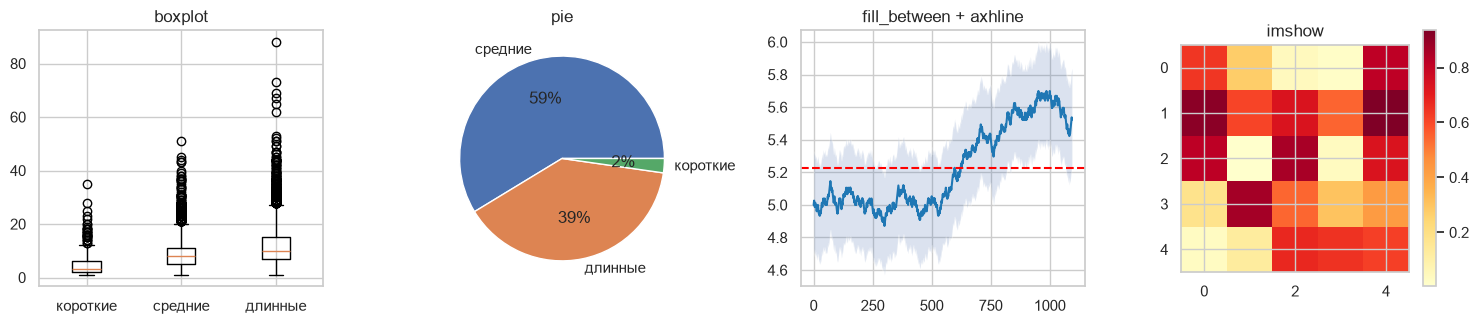

In [7]:
groups = [rec.loc[rec["kind"] == k, "n_steps"].dropna() for k in ["короткие", "средние", "длинные"]]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))

axes[0].boxplot(groups, tick_labels=["короткие", "средние", "длинные"]); axes[0].set_title("boxplot")

sizes = rec["kind"].value_counts()
axes[1].pie(sizes.values, labels=sizes.index, autopct="%.0f%%"); axes[1].set_title("pie")

yy = ratings[0]
axes[2].plot(yy, color="tab:blue"); axes[2].fill_between(range(len(yy)), yy - 0.3, yy + 0.3, alpha=0.2)
axes[2].axhline(yy.mean(), color="red", ls="--"); axes[2].set_title("fill_between + axhline")

im = axes[3].imshow(np.random.default_rng(0).random((5, 5)), cmap="YlOrRd")
plt.colorbar(im, ax=axes[3]); axes[3].set_title("imshow")
plt.tight_layout(); plt.show()

## 1.7 Оформление — 8 мин

**Текст:**
```python
ax.set_title("Заголовок")             ax.set_xlabel("Ось X")        ax.set_ylabel("Ось Y")
ax.set(title="…", xlabel="…", ylabel="…")      # всё сразу
ax.text(x, y, "текст")                          # подпись в координатах данных
ax.annotate("пик", xy=(x, y), xytext=(x2, y2), arrowprops=dict(arrowstyle="->"))   # стрелка
ax.text(x, y, r"$y(x)=\lambda e^{-\lambda x}$") # формула: в долларах, строка raw (r"…")
```
**Оси:**
```python
ax.set_xlim(0, 100); ax.set_ylim(0, 5)          # пределы
ax.set_yscale("log")                            # лог-шкала (экспонента становится прямой)
ax.set_xticks([0, 50, 100]); ax.set_xticklabels(["a", "b", "c"])   # свои засечки
ax.tick_params(axis="x", rotation=45)           # повернуть подписи
ax.grid(True, alpha=0.3); ax.invert_yaxis()
```
**Легенда:** `ax.legend(loc="upper right")` (`"best"`, `"lower left"`…), `ncol=2`, `frameon=False`, `title="Группы"`. Легенда берёт имена из `label=`. Нет `label` → нет записи.

**Цвета:** названия (`"red"`), hex (`"#1f77b4"`), стандартные `"C0"…"C9"` / `"tab:blue"`, серый строкой `"0.5"`.
**Стиль всей темы:** `plt.style.use("ggplot")`. **Размер шрифтов:** `plt.rcParams["font.size"] = 12`.

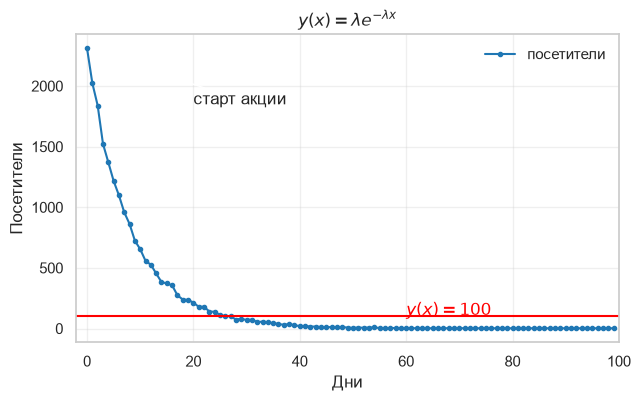

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
t = np.arange(len(visitors))
ax.plot(t, visitors, color="tab:blue", marker="o", ms=3, label="посетители")
ax.axhline(100, color="red"); ax.text(60, 110, "$y(x)=100$", color="red")       # линия-порог + подпись
ax.annotate("старт акции", xy=(0, visitors[0]), xytext=(20, visitors[0] * 0.8), arrowprops=dict(arrowstyle="->"))
ax.set(title=r"$y(x)=\lambda e^{-\lambda x}$", xlabel="Дни", ylabel="Посетители", xlim=(-2, 100))
ax.legend(loc="upper right", frameon=False); ax.grid(alpha=0.3)
plt.show()

## 1.8 Несколько графиков — `subplots` — 6 мин

`plt.subplots(строки, столбцы)` возвращает **`fig` и массив осей**:
- `plt.subplots(1, 2)` → `axes.shape == (2,)` → `axes[0]`, `axes[1]`
- `plt.subplots(2, 2)` → `axes.shape == (2, 2)` → `axes[0, 1]`; `axes.flat` / `axes.ravel()` — плоский список для цикла
- `plt.subplots(1, 1)` — **не** массив, а одна `ax`!

**Общие оси:** `sharex=True`, `sharey=True` (подписи оставляются только по краям; масштабирование связано).
**Не наезжают подписи:** `fig.tight_layout()` или `plt.subplots(..., layout="constrained")`. Расстояния вручную: `fig.subplots_adjust(wspace=0.4, hspace=0.3)`. Если подпись оси наезжает на соседа — `ax.set_ylabel("…", labelpad=10)` или `wspace`.
**Заголовок всей фигуры:** `fig.suptitle("…")` (а `ax.set_title` — одного графика).
**Две оси Y:** `ax2 = ax.twinx()` — общая ось X, своя Y справа.
**Разные размеры:** `plt.subplots(1, 2, gridspec_kw={"width_ratios": [2, 1]})` или `fig.subplot_mosaic("AAB;CCB")`.

(2, 2)


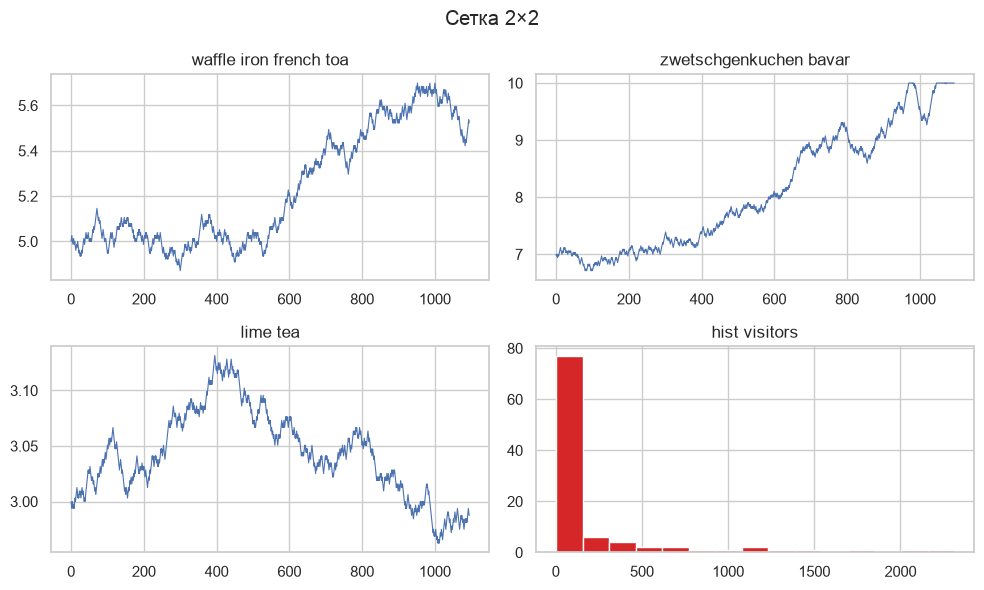

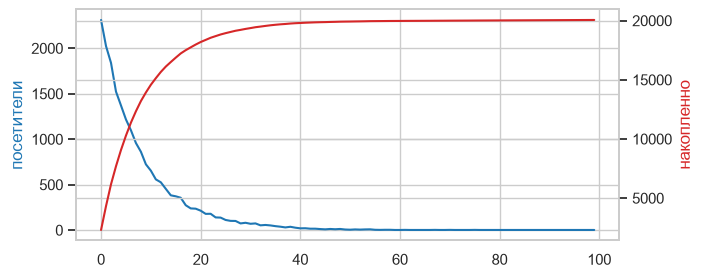

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=False)
print(axes.shape)
for ax_, name, y in zip(axes.flat[:3], names, ratings):       # цикл по осям
    ax_.plot(y, lw=0.8); ax_.set_title(name[:22])
axes[1, 1].hist(visitors, bins=15, color="tab:red"); axes[1, 1].set_title("hist visitors")
fig.suptitle("Сетка 2×2")
fig.tight_layout(); plt.show()

# две оси Y
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(visitors, color="tab:blue"); ax.set_ylabel("посетители", color="tab:blue")
ax2 = ax.twinx()
ax2.plot(np.cumsum(visitors), color="tab:red"); ax2.set_ylabel("накопленно", color="tab:red")
plt.show()

## 1.9 Даты на оси X — 5 мин

Чтобы по X были **годы и месяцы**, нужны настоящие даты:
```python
dates = pd.date_range("2019-01-01", "2021-12-30", freq="D")   # 1095 дат (шаг — день)
ax.plot(dates, y)
ax.xaxis.set_major_locator(mdates.YearLocator())              # крупные засечки — годы
ax.xaxis.set_minor_locator(mdates.MonthLocator())             # мелкие — месяцы
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))      # формат подписи: %Y год, %m месяц, %d день, %b янв
fig.autofmt_xdate()                                           # повернуть подписи, если слиплись
```
Длина `dates` должна **совпадать** с длиной `y` (1095!). 2020 — високосный.

1095 1095


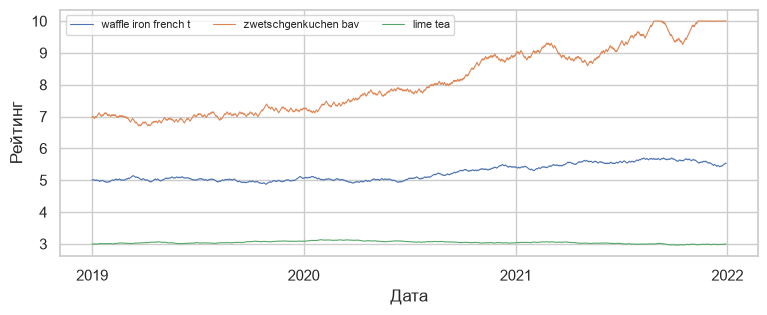

In [10]:
dates = pd.date_range("2019-01-01", "2021-12-30", freq="D")
print(len(dates), ratings.shape[1])
fig, ax = plt.subplots(figsize=(9, 3.2))
for y, n in zip(ratings, names): ax.plot(dates, y, label=n[:20], lw=0.8)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set(xlabel="Дата", ylabel="Рейтинг"); ax.legend(ncol=3, fontsize=8)
plt.show()

# 2. Графики из Pandas — `.plot` (7 мин)

У `Series` и `DataFrame` есть **свой** `.plot`, это обёртка над matplotlib. Результат — тот же `ax`, поэтому настраивается так же.

| Запись | Результат |
|---|---|
| `s.plot()` / `s.plot.line()` | линия (индекс = X) |
| `s.plot.bar()` / `.barh()` | столбцы (индекс = подписи) |
| `s.plot.hist(bins=20)` | гистограмма |
| `s.plot.pie(autopct="%.0f%%")` | круговая |
| `df.plot.scatter(x="a", y="b")` | точки |
| `df.plot.box()` | ящики по всем столбцам |
| `df.plot(subplots=True)` | каждый столбец — свой график |

**Главная связка:** `groupby` / `value_counts` / `pd.cut` → получили Series → `.plot.bar(ax=ax)`.
- `ax=` — нарисовать на **твоём** графике (нужно для сетки subplots).
- `title=`, `xlabel=`, `ylabel=`, `figsize=`, `color=`, `rot=0` (поворот подписей) — прямо в `.plot`.
- У `pie` ось Y подписана именем серии — убирай `ylabel=""`.
- `pd.cut(s, bins=[0, 5, 50, np.inf], labels=[…], right=False)` → интервалы `[0,5)`, `[5,50)`, `[50,∞)`. `right=False` значит: правая граница **не входит**.

,mean_steps,size
kind,,
короткие,4.990431,675
средние,8.581922,17607
длинные,11.917290,11718


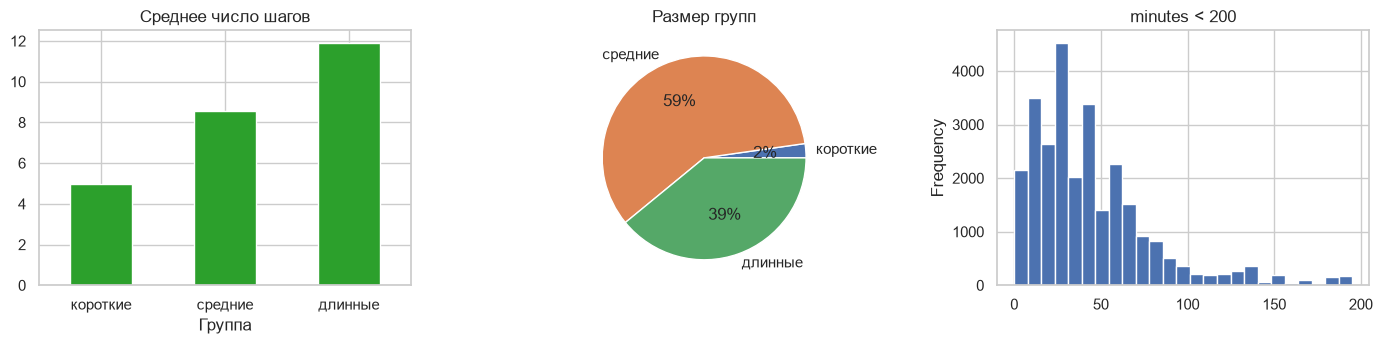

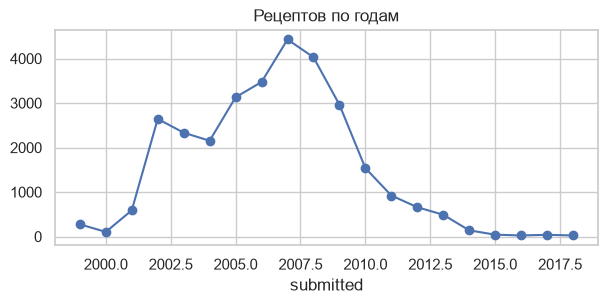

In [11]:
g = rec.groupby("kind", observed=True).agg(mean_steps=("n_steps", "mean"), size=("id", "size"))
display(g)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
g["mean_steps"].plot.bar(ax=axes[0], rot=0, title="Среднее число шагов", xlabel="Группа", color="tab:green")
g["size"].plot.pie(ax=axes[1], autopct="%.0f%%", title="Размер групп", ylabel="")
rec.loc[rec["minutes"] < 200, "minutes"].plot.hist(bins=25, ax=axes[2], edgecolor="white", title="minutes < 200")
plt.tight_layout(); plt.show()

# по годам: groupby года -> линия
rec.groupby(rec["submitted"].dt.year).size().plot(figsize=(7, 2.8), marker="o", title="Рецептов по годам")
plt.show()

# 3. Seaborn (10 мин)

**Seaborn** — надстройка над matplotlib: красивее по умолчанию и **сам считает** группы, средние, доверительные интервалы. Работает с `DataFrame`:
```python
sns.функция(data=df, x="столбец1", y="столбец2", hue="столбец3")
```
- `hue` — раскрасить по категории, `size` — размер по значению, `style` — форма маркера.
- Результат — **тот же `ax`** matplotlib → `.set_title`, `.set(…)` работают. Свой `ax`: `ax=axes[0]`.
- Тема: `sns.set_theme(style="whitegrid")`; `style`: `white`, `dark`, `ticks`. Контекст: `context="talk"` (крупнее шрифт). Палитра: `palette="Set2"`.

## 3.1 Два вида функций (запомнить!)
| | axes-level | figure-level |
|---|---|---|
| Функции | `scatterplot`, `lineplot`, `histplot`, `kdeplot`, `boxplot`, `violinplot`, `barplot`, `countplot`, `heatmap`, `regplot` | `relplot`, `displot`, `catplot`, `pairplot`, `jointplot`, `lmplot` |
| Рисуют | на **одном** `ax` (можно `ax=`) | **целую фигуру** (создают сами) |
| Возвращают | `Axes` | `FacetGrid` (`g.fig`, `g.axes`, `g.set_titles()`) |
| `ax=` | можно | **нельзя** |
| Разбить на панели | нет | `col="…"`, `row="…"` |

## 3.2 Связи двух признаков: `scatterplot`, `lineplot`, `regplot`
- `sns.scatterplot(data=df, x=, y=, hue=, size=, style=, alpha=)` — точки.
- `sns.lineplot(data=df, x=, y=, hue=)` — линия. **Если на один X несколько Y, сам считает среднее и рисует полосу 95% доверительного интервала.**
- `sns.regplot(data=df, x=, y=, scatter_kws={"alpha":.3})` — точки + линия линейной регрессии (быстрый ответ «есть ли линейная связь»).

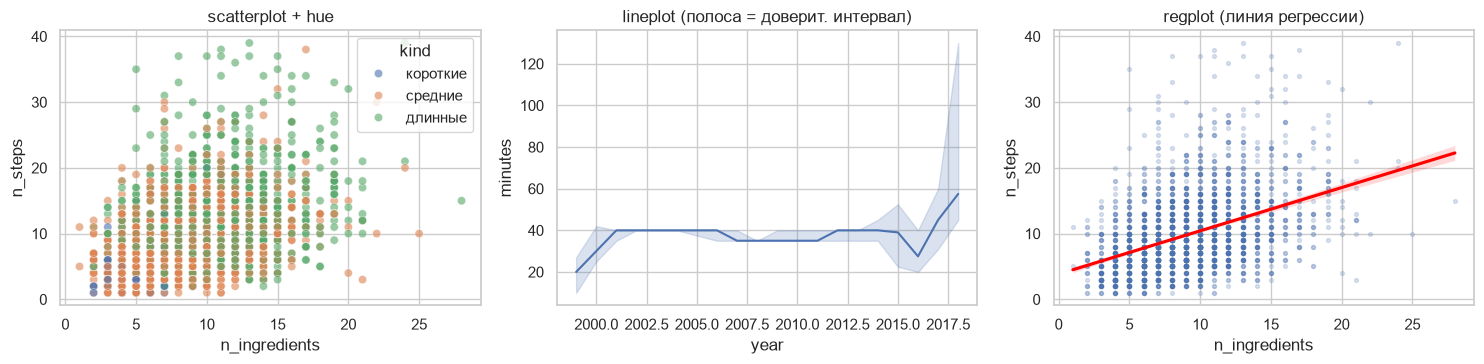

In [12]:
s = rec.dropna(subset=["n_steps", "n_ingredients"]).query("n_steps < 40").sample(3000, random_state=1)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

sns.scatterplot(data=s, x="n_ingredients", y="n_steps", hue="kind", alpha=0.6, ax=axes[0])
axes[0].set_title("scatterplot + hue")

yr = rec.assign(year=rec["submitted"].dt.year)
sns.lineplot(data=yr, x="year", y="minutes", estimator="median", ax=axes[1])
axes[1].set_title("lineplot (полоса = доверит. интервал)")

sns.regplot(data=s, x="n_ingredients", y="n_steps", scatter_kws={"alpha": 0.2, "s": 8}, line_kws={"color": "red"}, ax=axes[2])
axes[2].set_title("regplot (линия регрессии)")
plt.tight_layout(); plt.show()

## 3.3 Распределения: `histplot`, `kdeplot`, `displot`
- `sns.histplot(data=df, x="col", bins=30, kde=True, hue="cat", stat="density", element="step")` — гистограмма; `kde=True` добавляет сглаженную кривую плотности.
- `sns.kdeplot(data=df, x="col", hue="cat", fill=True)` — только плотность (удобно сравнивать группы).
- `hue` + `multiple="stack"|"dodge"|"layer"` — как совмещать группы.
- `sns.displot(…, col="cat")` — figure-level: по панели на группу.
- `common_norm=False` — нормировать группы по отдельности (если группы разного размера).

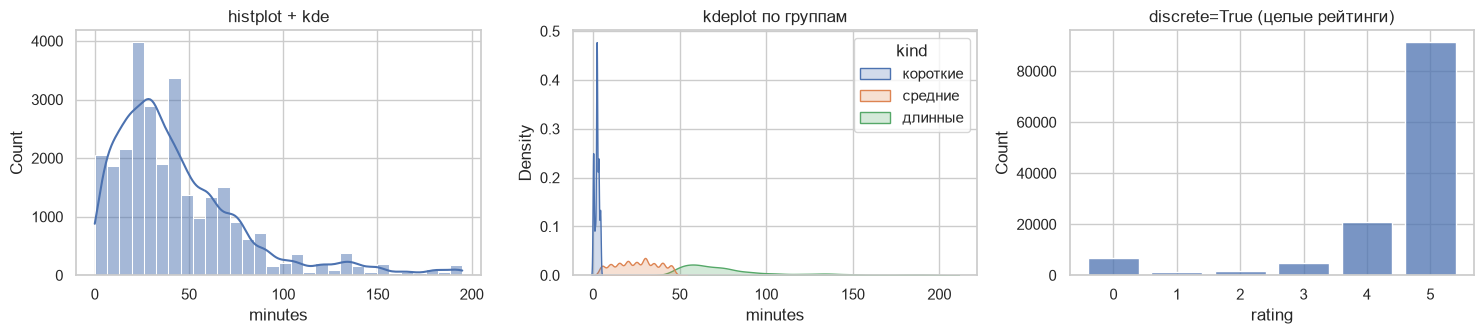

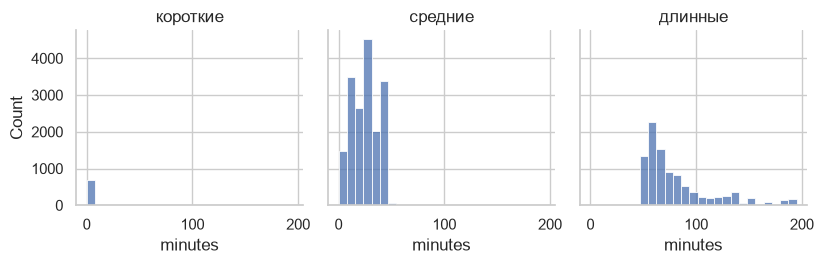

In [13]:
q = rec[rec["minutes"] < 200]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(data=q, x="minutes", bins=30, kde=True, ax=axes[0]); axes[0].set_title("histplot + kde")
sns.kdeplot(data=q, x="minutes", hue="kind", fill=True, common_norm=False, ax=axes[1]); axes[1].set_title("kdeplot по группам")
sns.histplot(data=rev, x="rating", discrete=True, shrink=0.8, ax=axes[2]); axes[2].set_title("discrete=True (целые рейтинги)")
plt.tight_layout(); plt.show()

g = sns.displot(data=q, x="minutes", col="kind", bins=25, height=2.8)    # figure-level: панель на группу
g.set_titles("{col_name}")

## 3.4 Категории: `countplot`, `barplot`, `boxplot`, `violinplot`, `stripplot`
| Функция | Что показывает |
|---|---|
| `countplot(data, x="cat")` | сколько строк в каждой категории (сам считает, как `value_counts`) |
| `barplot(data, x="cat", y="num")` | **среднее** `num` по категориям + доверительный интервал (усы). Не сумма! |
| `boxplot(data, x="cat", y="num")` | ящик: медиана, квартили, выбросы |
| `violinplot` | форма распределения по группам |
| `stripplot` / `swarmplot` | каждая точка отдельно |
| `catplot(kind=…, col=…)` | всё то же, figure-level |

📌 Параметры: `order=[…]` (порядок категорий), `hue=`, `estimator="median"` (вместо среднего), `errorbar=None` (убрать усы), `orient="h"`.

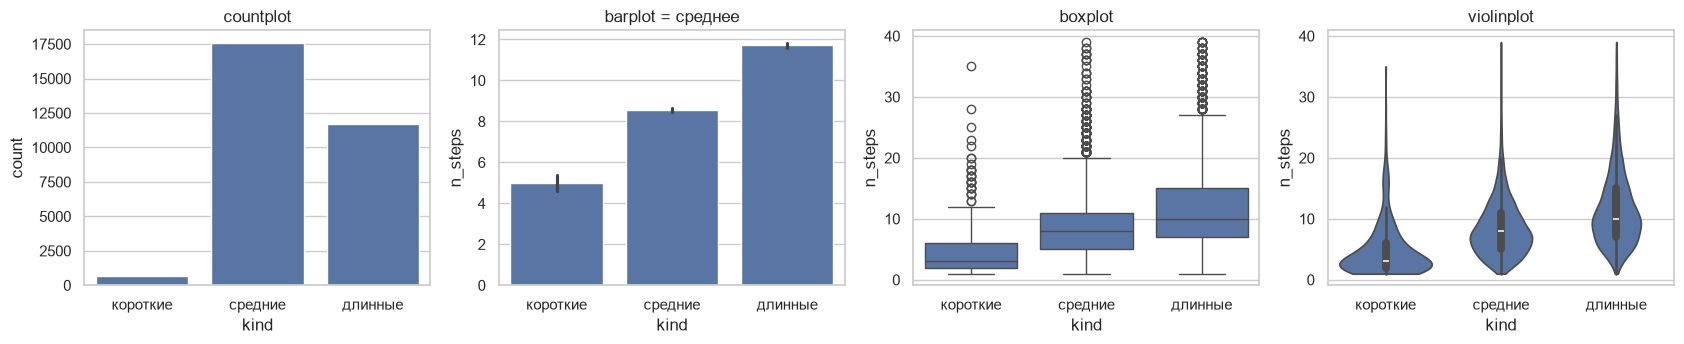

In [14]:
order = ["короткие", "средние", "длинные"]
ss = rec.dropna(subset=["n_steps"]).query("n_steps < 40")
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
sns.countplot(data=rec, x="kind", order=order, ax=axes[0]);                      axes[0].set_title("countplot")
sns.barplot(data=ss, x="kind", y="n_steps", order=order, ax=axes[1]);             axes[1].set_title("barplot = среднее")
sns.boxplot(data=ss, x="kind", y="n_steps", order=order, ax=axes[2]);             axes[2].set_title("boxplot")
sns.violinplot(data=ss, x="kind", y="n_steps", order=order, cut=0, ax=axes[3]);   axes[3].set_title("violinplot")
plt.tight_layout(); plt.show()

## 3.5 Корреляции: `heatmap` — ГЛАВНОЕ для контрольной
1. Берёшь числовые столбцы: `corr = df[["a","b","c"]].corr()` — матрица коэффициентов Пирсона от −1 до 1.
   - **+1** — идеальная прямая связь, **0** — линейной связи нет, **−1** — обратная. На диагонали всегда 1.
   - ⚠️ Корреляция **≠ причинность**, ловит только **линейную** связь, чувствительна к выбросам.
2. Рисуешь: `sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrRd", vmin=-1, vmax=1, ax=ax)`
   - `annot=True` — числа в ячейках, `fmt=".2f"` — 2 знака, `cmap` — палитра, `vmin/vmax` — границы шкалы,
     `center=0` — середина шкалы, `square=True` — квадратные ячейки, `mask=` — скрыть часть (например, верхний треугольник).

**Палитры (`cmap`):** последовательные (одна шкала от меньшего к большему): `YlOrRd`, `Blues`, `viridis`; расходящиеся (есть нейтральная середина, подходят для корреляций): `coolwarm`, `RdBu_r`, `vlag`; категориальные (для `hue`): `Set2`, `tab10`, `deep`.

**Как читать:** сильная связь — |r| > 0.7; средняя — 0.3–0.7; слабая — < 0.3.

,minutes,n_steps,n_ingredients,rating
minutes,1.00,0.03,-0.01,-0.03
n_steps,0.03,1.00,0.29,-0.02
n_ingredients,-0.01,0.29,1.00,0.00
rating,-0.03,-0.02,0.00,1.00


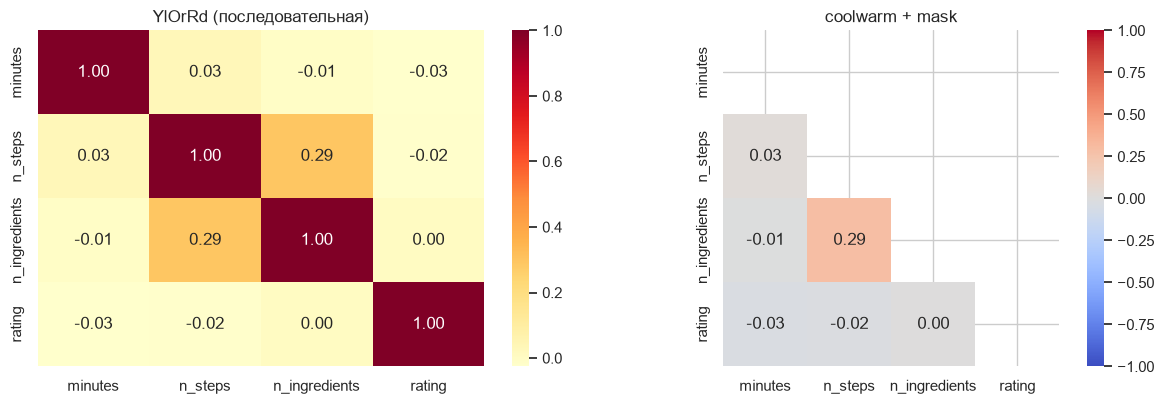

In [15]:
merged = rec.merge(rev, left_on="id", right_on="recipe_id")        # рецепт + его отзывы
corr = merged[["minutes", "n_steps", "n_ingredients", "rating"]].corr()
display(corr.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrRd", ax=axes[0]); axes[0].set_title("YlOrRd (последовательная)")
mask = np.triu(np.ones_like(corr, dtype=bool))                       # скрыть верхний треугольник (дубль)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=axes[1])
axes[1].set_title("coolwarm + mask")
plt.tight_layout(); plt.show()

## 3.7 Типичные ошибки (прочитай — сэкономишь время)

| Симптом | Причина → решение |
|---|---|
| Все подписи слиплись, наезжают | `fig.tight_layout()` / `layout="constrained"` / `labelpad` |
| `TypeError: 'Axes' object is not subscriptable` | `subplots(1,1)` возвращает одну ось, а не массив; индексировать не надо |
| `axes[i]` на сетке 2×2 падает | у сетки `axes[i, j]`; для цикла `axes.flat` |
| Легенды нет | забыл `label=` или `ax.legend()` |
| Pie с подписью «n_steps» сбоку | `ylabel=""` |
| `sns.relplot(..., ax=ax)` ошибка | figure-level не принимает `ax` |
| На оси X «числа 18000» вместо дат | в X не `datetime`; `pd.to_datetime` / `pd.date_range` |
| Длины X и Y не совпали | `ValueError: x and y must have same first dimension` |
| `barplot` показал не то | он считает **среднее**, для количества — `countplot` |
| Бары слишком тонкие/гистограмма странная | неверный `bins`; выбросы → `range=` или фильтр |
| Лог-шкала и нули | `log(0)` не определён; значения ≤ 0 не рисуются |

# 4. ТЕСТЫ (15 мин)

Пиши код в ячейке **над** линией `--- проверка ---`, запускай. Проверка печатает `[OK]` или `[X]`, плохие попадут в журнал ошибок.
Порядок специально перемешан (Matplotlib, Pandas-графики, Seaborn), как на контрольной. Не получается 5 минут → смотри подсказку, потом в конце файла «Эталон».

**Часть A — Matplotlib**

**A1.** Синус и косинус на одном графике. `x` дан. Линия `sin` (label `"sin"`), линия `cos` (label `"cos"`), у линий разные цвета. Заголовок `"Синус и косинус"`, подписи осей `"x"` и `"y"`, легенда, сетка.

<details><summary>Подсказка (после своей попытки)</summary>

`ax.plot(x, y, label=…)` два раза; `ax.set(title=…, xlabel=…, ylabel=…)`; `ax.legend()`; `ax.grid(True)`.

</details>

[X]  2 линии
[X]  title
[X]  xlabel/ylabel
[X]  легенда sin, cos
[X]  разные цвета
[OK] сетка включена


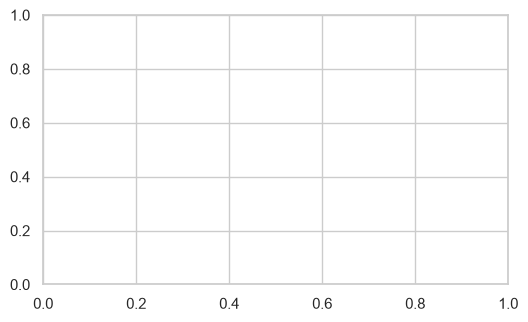

In [16]:
x = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
# твой код

# --- проверка, не трогай ---
ok("2 линии", lambda: len(ax.lines) == 2)
ok("title", lambda: ax.get_title() == "Синус и косинус")
ok("xlabel/ylabel", lambda: ax.get_xlabel() == "x" and ax.get_ylabel() == "y")
ok("легенда sin, cos", lambda: leg(ax) == ["sin", "cos"])
ok("разные цвета", lambda: len(set(colors(ax))) == 2)
ok("сетка включена", lambda: ax.xaxis.get_gridlines()[0].get_visible())

**A5.** Сетка 2×2 (`figsize=(9, 6)`). `[0,0]` — линия `visitors`; `[0,1]` — гистограмма `ratings[0]` на 15 корзин; `[1,0]` — столбцы среднего рейтинга трёх рецептов (3 столбца); `[1,1]` — `boxplot` трёх рядов `ratings` (список строк). Общий заголовок фигуры `"Обзор"`, затем `tight_layout`.

<details><summary>Подсказка (после своей попытки)</summary>

К сетке обращаются `axes[i, j]`. Ряды для boxplot: `list(ratings)` — список из 3 массивов.

</details>

[OK] сетка 2x2
[X]  [0,0] одна линия
[X]  [0,1] 15 корзин
[X]  [1,0] 3 столбца
[X]  [1,1] boxplot (3 ящика)
[X]  suptitle


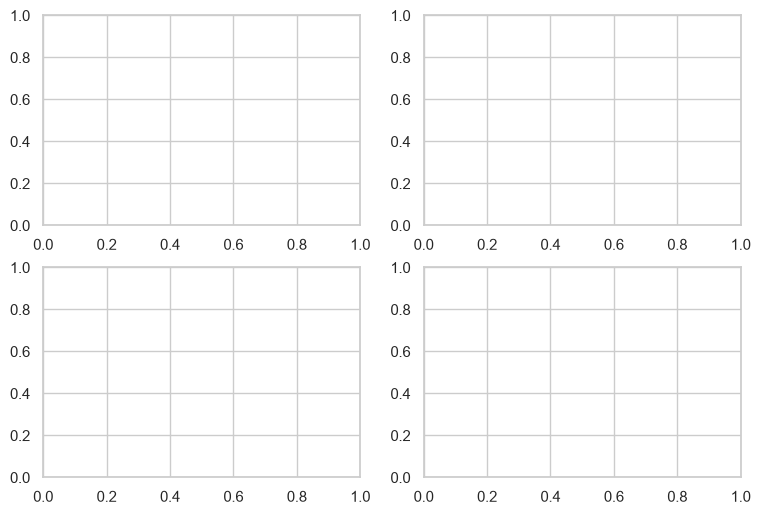

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
# твой код

# --- проверка, не трогай ---
ok("сетка 2x2", lambda: axes.shape == (2, 2))
ok("[0,0] одна линия", lambda: len(axes[0, 0].lines) == 1 and len(axes[0, 0].lines[0].get_ydata()) == 100)
ok("[0,1] 15 корзин", lambda: len(axes[0, 1].patches) == 15)
ok("[1,0] 3 столбца", lambda: len(axes[1, 0].patches) == 3 and np.allclose([p.get_height() for p in axes[1, 0].patches], ratings.mean(axis=1)))
ok("[1,1] boxplot (3 ящика)", lambda: len(axes[1, 1].lines) >= 15)
ok("suptitle", lambda: sup(fig) == "Обзор")

**Часть B — задания ЛР5 (1–4), как на лабораторной**

**ЛР5·1.** Три временных ряда `ratings` в **одной** системе координат: по X номер дня, по Y рейтинг. У рядов разные цвета, легенда с названиями из `names`, подписи осей `"Номер дня"` и `"Средний рейтинг"`, заголовок `"Изменение среднего рейтинга трех рецептов"`.

<details><summary>Подсказка (после своей попытки)</summary>

Цикл `for y, n in zip(ratings, names): ax.plot(y, label=n)`: цвета назначатся сами.

</details>

[X]  3 линии
[OK] данные = ratings
[X]  разные цвета
[X]  легенда = names
[X]  подписи осей
[X]  заголовок


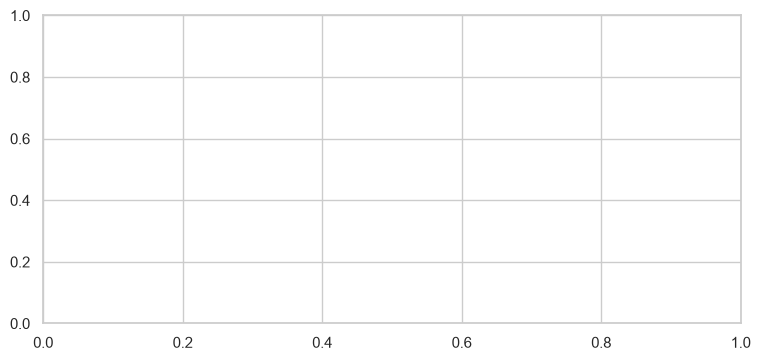

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
# твой код

# --- проверка, не трогай ---
ok("3 линии", lambda: len(ax.lines) == 3)
ok("данные = ratings", lambda: all(np.allclose(l.get_ydata(), r) for l, r in zip(ax.lines, ratings)))
ok("разные цвета", lambda: len(set(colors(ax))) == 3)
ok("легенда = names", lambda: leg(ax) == names)
ok("подписи осей", lambda: (ax.get_xlabel(), ax.get_ylabel()) == ("Номер дня", "Средний рейтинг"))
ok("заголовок", lambda: ax.get_title() == "Изменение среднего рейтинга трех рецептов")

**ЛР5·2.** То же, но по X — **даты** `pd.date_range` с `2019-01-01` по `2021-12-30` (шаг день). Крупные засечки по годам (`YearLocator`), мелкие по месяцам (`MonthLocator`). Подпись X — `"Дата"`; остальное как в ЛР5·1.

<details><summary>Подсказка (после своей попытки)</summary>

`dates = pd.date_range(...)`, затем `ax.plot(dates, y)`; локаторы через `ax.xaxis.set_major_locator(mdates.YearLocator())`.

</details>

[X]  3 линии, 1095 точек
[X]  по X даты
[X]  major = годы
[X]  minor = месяцы
[X]  подписи: Дата / Средний рейтинг
[X]  легенда = names


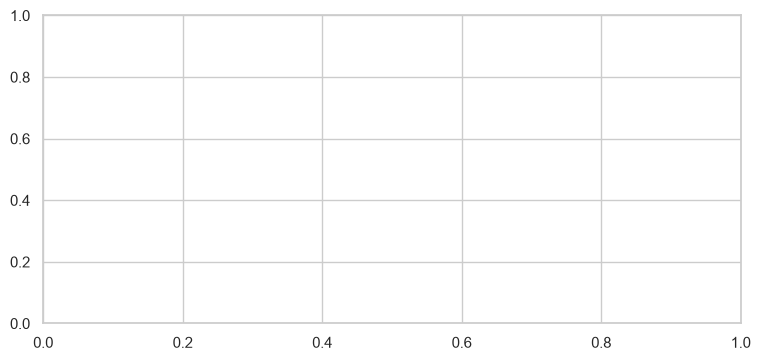

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
# твой код

# --- проверка, не трогай ---
ok("3 линии, 1095 точек", lambda: len(ax.lines) == 3 and all(len(l.get_xdata()) == 1095 for l in ax.lines))
ok("по X даты", lambda: np.issubdtype(np.asarray(ax.lines[0].get_xdata()).dtype, np.datetime64) or hasattr(ax.lines[0].get_xdata()[0], "year"))
ok("major = годы", lambda: isinstance(ax.xaxis.get_major_locator(), mdates.YearLocator))
ok("minor = месяцы", lambda: isinstance(ax.xaxis.get_minor_locator(), mdates.MonthLocator))
ok("подписи: Дата / Средний рейтинг", lambda: (ax.get_xlabel(), ax.get_ylabel()) == ("Дата", "Средний рейтинг"))
ok("легенда = names", lambda: leg(ax) == names)

**ЛР5·3.** Раздели рисунок из ЛР5·2 на **три графика друг под другом** с общей осью X (`sharex=True`), на каждом — свой ряд своим цветом, у каждого своя легенда. Подпись `"Дата"` у нижнего. `dates` дан.

<details><summary>Подсказка (после своей попытки)</summary>

`fig, axes = plt.subplots(3, 1, sharex=True)`; цвет `f"C{i}"`; цикл по `zip(axes, ratings, names)`.

</details>

In [20]:
dates = pd.date_range("2019-01-01", "2021-12-30", freq="D")
# твой код: должны получиться fig и axes

# --- проверка, не трогай ---
ok("3 графика", lambda: len(fig.axes) == 3)
ok("общая ось X", lambda: axes[0].get_shared_x_axes().joined(axes[0], axes[2]))
ok("на каждом одна линия", lambda: all(len(a.lines) == 1 for a in axes))
ok("легенды = names", lambda: [leg(a)[0] for a in axes] == names)
ok("разные цвета", lambda: len({colors(a)[0] for a in axes}) == 3)
ok("нижняя подпись Дата", lambda: axes[2].get_xlabel() == "Дата")

[X]  3 графика
[X]  общая ось X
[X]  на каждом одна линия
[X]  легенды = names
[X]  разные цвета
[X]  нижняя подпись Дата


**ЛР5·4.** По `visitors` два графика-ломаных **рядом**: слева линейная шкала, справа вертикальная ось в **логарифме**. На обоих: красная горизонтальная линия на `y=100`, подпись над ней `"$y(x)=100$"`, подпись над графиком `"$y(x)=\lambda e^{-\lambda x}$"` (заголовок оси), подписи осей `"Количество дней с момента акции"` и `"Число посетителей"`. Общий заголовок фигуры `"Изменение количества пользователей в линейном и логарифмическом масштабе"`.

<details><summary>Подсказка (после своей попытки)</summary>

Цикл по `zip(axes, ["linear", "log"])`: `ax.set_yscale(scale)`, `ax.axhline(100, color="red")`, `ax.text(x, y, …)`. Формулы в `r"…"`.

</details>

[X]  слева linear, справа log
[X]  в каждом график visitors
[X]  красная линия y=100
[X]  текст y(x)=100
[X]  формула в заголовках
[X]  подписи осей
[X]  suptitle


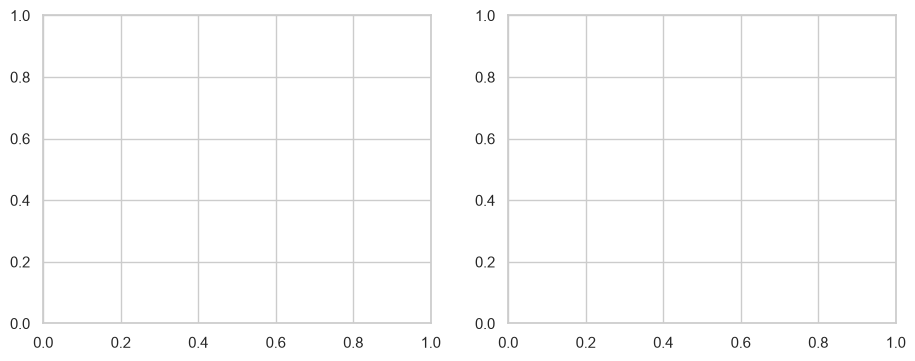

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# твой код

# --- проверка, не трогай ---
ok("слева linear, справа log", lambda: axes[0].get_yscale() == "linear" and axes[1].get_yscale() == "log")
ok("в каждом график visitors", lambda: all(any(np.allclose(l.get_ydata(), visitors) for l in a.lines) for a in axes))
ok("красная линия y=100", lambda: all(any(mcolors.same_color(l.get_color(), "red") and set(np.asarray(l.get_ydata(), float)) == {100.0} for l in a.lines) for a in axes))
ok("текст y(x)=100", lambda: all(any(t.get_text() == "$y(x)=100$" for t in a.texts) for a in axes))
ok("формула в заголовках", lambda: all(a.get_title() == r"$y(x)=\lambda e^{-\lambda x}$" for a in axes))
ok("подписи осей", lambda: all((a.get_xlabel(), a.get_ylabel()) == ("Количество дней с момента акции", "Число посетителей") for a in axes))
ok("suptitle", lambda: sup(fig) == "Изменение количества пользователей в линейном и логарифмическом масштабе")

**Часть C — Pandas-графики и Seaborn (ЛР5·5–8)**

**ЛР5·5.** Рецепты по `minutes`: короткие (`<5`), средние (`5…<50`), длинные (`≥50`) — это столбец `rec["kind"]`. Для каждой группы посчитай среднее `n_steps` и размер группы (в `g`). Рядом (1×2) постройте **методами pandas**: слева столбцы среднего `n_steps` по группам, справа круговая диаграмма размеров. Подписи: слева X `"Группа рецептов"`, Y `"Средняя длительность"`; справа заголовок `"Размеры групп рецептов"`.

<details><summary>Подсказка (после своей попытки)</summary>

`rec.groupby("kind", observed=True).agg(mean_steps=("n_steps","mean"), size=("id","size"))`, затем `g["mean_steps"].plot.bar(ax=axes[0])` и `g["size"].plot.pie(ax=axes[1])`.

</details>

[X]  g: 3 группы
[X]  столбцов 3, высоты = среднее n_steps
[X]  секторов 3 (pie)
[X]  доли pie ~ размеры
[X]  подписи слева
[X]  заголовок справа


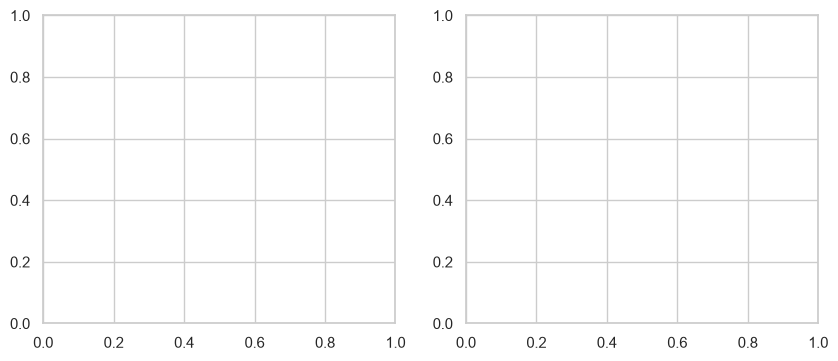

In [22]:
g = ...
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# твой код

# --- проверка, не трогай ---
exp_mean = rec.groupby("kind", observed=True)["n_steps"].mean().values
exp_size = rec.groupby("kind", observed=True).size().values
ok("g: 3 группы", lambda: len(g) == 3)
ok("столбцов 3, высоты = среднее n_steps", lambda: len(axes[0].patches) == 3 and np.allclose([p.get_height() for p in axes[0].patches], exp_mean))
ok("секторов 3 (pie)", lambda: len(axes[1].patches) == 3)
ok("доли pie ~ размеры", lambda: np.allclose(sorted(g.iloc[:, 1].values if g.shape[1] > 1 else g.values), sorted(exp_size)))
ok("подписи слева", lambda: (axes[0].get_xlabel(), axes[0].get_ylabel()) == ("Группа рецептов", "Средняя длительность"))
ok("заголовок справа", lambda: axes[1].get_title() == "Размеры групп рецептов")

**ЛР5·6.** Из `rev` оставь отзывы за **2008** и **2009** годы (`r08`, `r09`). Две гистограммы `rating` через `.plot.hist` **рядом**: слева 2008, справа 2009. Общий заголовок фигуры `"Гистограммы рейтинга отзывов в 2008 и 2009 годах"`. Подпись оси Y справа не должна наезжать на левый график (`tight_layout`).

<details><summary>Подсказка (после своей попытки)</summary>

`rev[rev["date"].dt.year == 2008]` — маска по году; `r08["rating"].plot.hist(ax=axes[0])`; `fig.tight_layout()` разведёт подписи.

</details>

[X]  r08 только 2008
[X]  r09 только 2009
[X]  гистограмма слева = 2008
[X]  гистограмма справа = 2009
[X]  suptitle


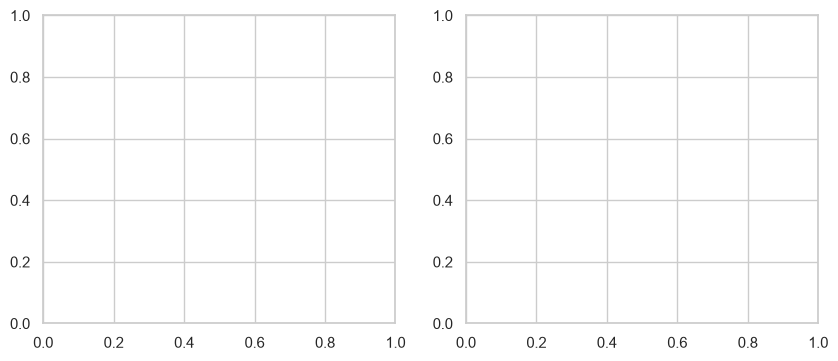

In [23]:
r08 = ...
r09 = ...
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# твой код

# --- проверка, не трогай ---
ok("r08 только 2008", lambda: (r08["date"].dt.year == 2008).all() and len(r08) == int((rev["date"].dt.year == 2008).sum()))
ok("r09 только 2009", lambda: (r09["date"].dt.year == 2009).all() and len(r09) == int((rev["date"].dt.year == 2009).sum()))
ok("гистограмма слева = 2008", lambda: int(round(sum(p.get_height() for p in axes[0].patches))) == len(r08))
ok("гистограмма справа = 2009", lambda: int(round(sum(p.get_height() for p in axes[1].patches))) == len(r09))
ok("suptitle", lambda: sup(fig) == "Гистограммы рейтинга отзывов в 2008 и 2009 годах")

**ЛР5·7.** `seaborn`: диаграмма рассеяния `n_steps` (X) и `n_ingredients` (Y) из `rec`, цвет по `kind` (`hue`). Заголовок `"Диаграмма рассеяния n_steps и n_ingredients"`. Ниже в markdown-ячейке допиши вывод: есть ли линейная зависимость.

<details><summary>Подсказка (после своей попытки)</summary>

`sns.scatterplot(data=rec, x="n_steps", y="n_ingredients", hue="kind", ax=ax)`; пропуски seaborn выкидывает сам.

</details>

[X]  точек = строк без пропусков
[X]  легенда: 3 группы
[X]  заголовок
[X]  оси n_steps / n_ingredients


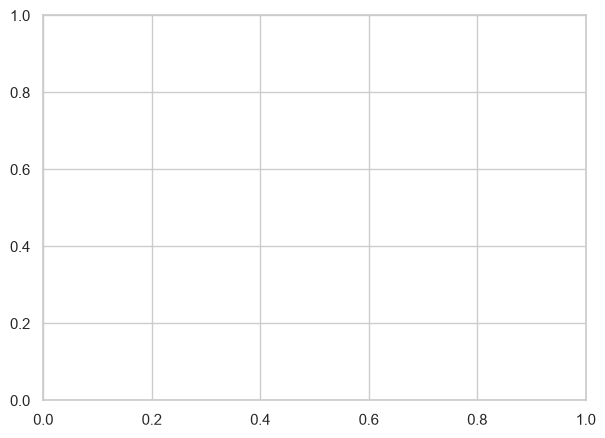

In [24]:
fig, ax = plt.subplots(figsize=(7, 5))
# твой код

# --- проверка, не трогай ---
n_ok = int(rec[["n_steps", "n_ingredients"]].notna().all(axis=1).sum())
ok("точек = строк без пропусков", lambda: sum(len(c.get_offsets()) for c in ax.collections) == n_ok)
ok("легенда: 3 группы", lambda: {"короткие", "средние", "длинные"} <= set(leg(ax)))
ok("заголовок", lambda: ax.get_title() == "Диаграмма рассеяния n_steps и n_ingredients")
ok("оси n_steps / n_ingredients", lambda: (ax.get_xlabel(), ax.get_ylabel()) == ("n_steps", "n_ingredients"))

**Мой вывод к ЛР5·7** (допиши): *есть ли линейная связь n_steps и n_ingredients? почему?*  →  …

**ЛР5·8.** Объедини `rec` и `rev` (`id == recipe_id`) в `merged`. Построй матрицу корреляций `corr` по `minutes`, `n_steps`, `n_ingredients`, `rating` и нарисуй `sns.heatmap` с числами в ячейках, палитрой `YlOrRd`, заголовком `"Корреляционная матрица числовых столбцов таблиц recipes и reviews"`.

<details><summary>Подсказка (после своей попытки)</summary>

`rec.merge(rev, left_on="id", right_on="recipe_id")` → `[[4 столбца]].corr()` → `sns.heatmap(corr, annot=True, cmap="YlOrRd", ax=ax)`.

</details>

[X]  merged: строки есть, рейтинг есть
[X]  corr 4x4 и диагональ = 1
[X]  16 подписей в ячейках
[X]  палитра YlOrRd
[X]  заголовок


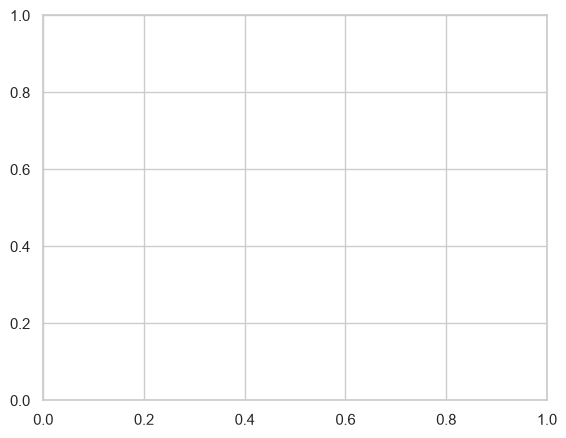

In [25]:
merged = ...
corr = ...
fig, ax = plt.subplots(figsize=(6.5, 5))
# твой код

# --- проверка, не трогай ---
ok("merged: строки есть, рейтинг есть", lambda: len(merged) > 100000 and "rating" in merged and "minutes" in merged)
ok("corr 4x4 и диагональ = 1", lambda: corr.shape == (4, 4) and np.allclose(np.diag(corr), 1))
ok("16 подписей в ячейках", lambda: len(ax.texts) == 16)
ok("палитра YlOrRd", lambda: ax.collections[0].get_cmap().name == "YlOrRd")
ok("заголовок", lambda: ax.get_title() == "Корреляционная матрица числовых столбцов таблиц recipes и reviews")

**Часть D — Seaborn: дополнительные задачи**

**D1.** Гистограмма `minutes` (только `minutes < 200`) через `sns.histplot`: 30 корзин, с кривой плотности (`kde`), раскраска по `kind` (`hue`). Заголовок `"minutes по группам"`.

<details><summary>Подсказка (после своей попытки)</summary>

`sns.histplot(data=q, x="minutes", bins=30, kde=True, hue="kind", ax=ax)`.

</details>

[X]  есть kde-кривые (линии)
[X]  есть столбцы гистограммы
[X]  легенда 3 группы
[X]  title


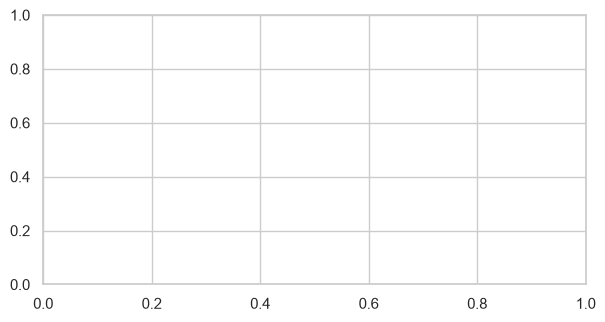

In [26]:
q = rec[rec["minutes"] < 200]
fig, ax = plt.subplots(figsize=(7, 3.5))
# твой код

# --- проверка, не трогай ---
ok("есть kde-кривые (линии)", lambda: len(ax.lines) >= 1)
ok("есть столбцы гистограммы", lambda: len(ax.patches) > 30)
ok("легенда 3 группы", lambda: {"короткие", "средние", "длинные"} <= set(leg(ax)))
ok("title", lambda: ax.get_title() == "minutes по группам")

**D3.** Сколько отзывов на каждую оценку (0…5): `sns.countplot` по `rating` из `rev`. Заголовок `"Распределение оценок"`, ось Y `"Отзывов"`.

<details><summary>Подсказка (после своей попытки)</summary>

`sns.countplot(data=rev, x="rating", ax=ax)`: сам считает количество.

</details>

[X]  6 столбцов
[X]  высоты = число отзывов
[X]  title
[X]  ylabel


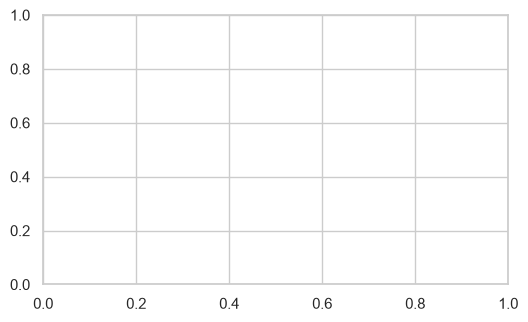

In [27]:
fig, ax = plt.subplots(figsize=(6, 3.5))
# твой код

# --- проверка, не трогай ---
cnt = rev["rating"].value_counts().sort_index().values
ok("6 столбцов", lambda: len(ax.patches) == 6)
ok("высоты = число отзывов", lambda: np.allclose([p.get_height() for p in ax.patches], cnt))
ok("title", lambda: ax.get_title() == "Распределение оценок")
ok("ylabel", lambda: ax.get_ylabel() == "Отзывов")

# 5. Финал (5 мин)

## 5.1 Журнал ошибок
Запусти ячейку: она покажет, что не прошло. Это твой список на повторение перед контрольной.

In [28]:
print("Не прошли проверки:", sorted(set(ERRORS)) or "— всё зелёное")
print("\nМои заметки:")
for i, t in enumerate(NOTES, 1): print(f"{i}. {t}")

Не прошли проверки: ['16 подписей в ячейках', '2 линии', '3 графика', '3 линии', '3 линии, 1095 точек', '6 столбцов', '[0,0] одна линия', '[0,1] 15 корзин', '[1,0] 3 столбца', '[1,1] boxplot (3 ящика)', 'corr 4x4 и диагональ = 1', 'g: 3 группы', 'major = годы', 'merged: строки есть, рейтинг есть', 'minor = месяцы', 'r08 только 2008', 'r09 только 2009', 'suptitle', 'title', 'xlabel/ylabel', 'ylabel', 'в каждом график visitors', 'высоты = число отзывов', 'гистограмма слева = 2008', 'гистограмма справа = 2009', 'доли pie ~ размеры', 'есть kde-кривые (линии)', 'есть столбцы гистограммы', 'заголовок', 'заголовок справа', 'красная линия y=100', 'легенда 3 группы', 'легенда = names', 'легенда sin, cos', 'легенда: 3 группы', 'легенды = names', 'на каждом одна линия', 'нижняя подпись Дата', 'общая ось X', 'оси n_steps / n_ingredients', 'палитра YlOrRd', 'по X даты', 'подписи осей', 'подписи слева', 'подписи: Дата / Средний рейтинг', 'разные цвета', 'секторов 3 (pie)', 'слева linear, справа log'

## 5.2 Карточки на 60 секунд (отвечай вслух, потом раскрывай)

<details><summary>1. Шаблон графика из пяти шагов?</summary>
<code>fig, ax = plt.subplots(figsize=…)</code> → рисуем <code>ax.plot/scatter/bar/hist</code> → <code>ax.set(title, xlabel, ylabel)</code> → <code>ax.legend()</code> → <code>plt.show()</code>.
</details>

<details><summary>2. Как сделать подписи, чтобы не наезжали?</summary>
<code>fig.tight_layout()</code> (или <code>layout="constrained"</code>), <code>labelpad</code>, <code>wspace</code>.
</details>

<details><summary>3. Как сделать три графика друг под другом с общей осью X?</summary>
<code>fig, axes = plt.subplots(3, 1, sharex=True)</code>, дальше цикл <code>for ax, y in zip(axes, ys)</code>.
</details>

<details><summary>4. Как поставить годы крупно и месяцы мелко?</summary>
<code>ax.xaxis.set_major_locator(mdates.YearLocator())</code> и <code>set_minor_locator(mdates.MonthLocator())</code>; на X — <code>pd.date_range</code>.
</details>

<details><summary>5. Pandas → график: цепочка?</summary>
<code>groupby/value_counts/pd.cut</code> → Series → <code>.plot.bar(ax=ax)</code> / <code>.plot.pie(autopct=…, ylabel="")</code> / <code>.plot.hist(ax=ax)</code>.
</details>

<details><summary>6. Seaborn: heatmap корреляций за три шага?</summary>
<code>corr = df[[…]].corr()</code> → <code>sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax)</code> → <code>ax.set_title(…)</code>.
</details>

<details><summary>7. axes-level vs figure-level?</summary>
axes-level (<code>scatterplot, histplot, boxplot, heatmap…</code>) рисуют на твоём <code>ax</code> и принимают <code>ax=</code>. Figure-level (<code>relplot, displot, catplot, pairplot…</code>) создают фигуру сами, возвращают <code>FacetGrid</code>, умеют <code>col=</code>.
</details>

<details><summary>8. barplot vs countplot?</summary>
<code>countplot</code> — сколько строк в категории. <code>barplot</code> — <b>среднее</b> числа по категории + интервал.
</details>

**План повторения:** сегодня → через 1 день прогнать только задания с `[X]` → за день до контрольной перерешать A1, ЛР5·4, ЛР5·5, ЛР5·8 **без подсказок**.

# Эталон (открывай после двух своих попыток)
Решения всех заданий. Каждая ячейка самодостаточна, но использует данные из ячейки 0 и (для ЛР5·2/3) переменные заданий.

### A1

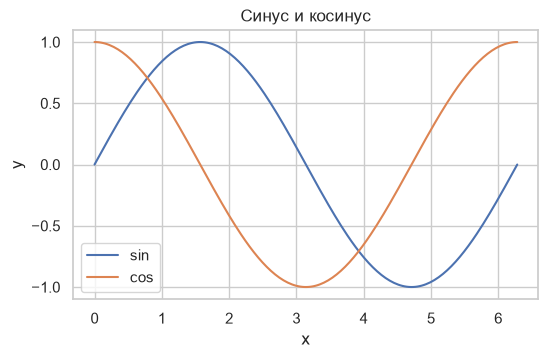

In [29]:
x = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(x, np.sin(x), label="sin")
ax.plot(x, np.cos(x), label="cos")
ax.set(title="Синус и косинус", xlabel="x", ylabel="y")
ax.legend(); ax.grid(True)

### A5

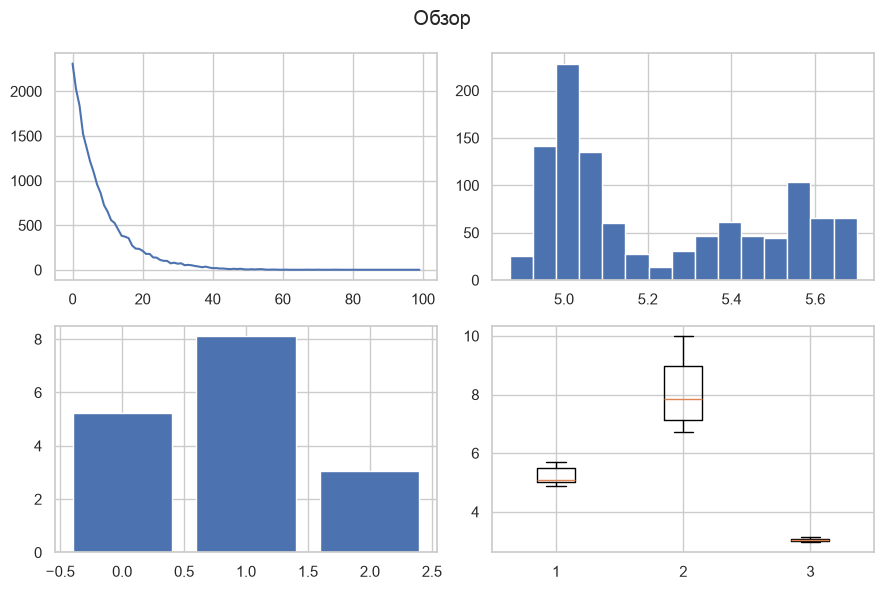

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
axes[0, 0].plot(visitors)
axes[0, 1].hist(ratings[0], bins=15)
axes[1, 0].bar(range(3), ratings.mean(axis=1))
axes[1, 1].boxplot(list(ratings))
fig.suptitle("Обзор")
fig.tight_layout()

### ЛР5·1

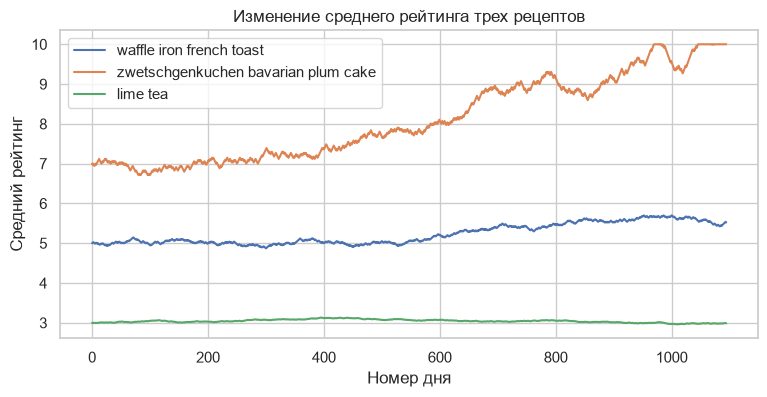

In [31]:
fig, ax = plt.subplots(figsize=(9, 4))
for y, n in zip(ratings, names):
    ax.plot(y, label=n)
ax.set(xlabel="Номер дня", ylabel="Средний рейтинг", title="Изменение среднего рейтинга трех рецептов")
ax.legend()

### ЛР5·2

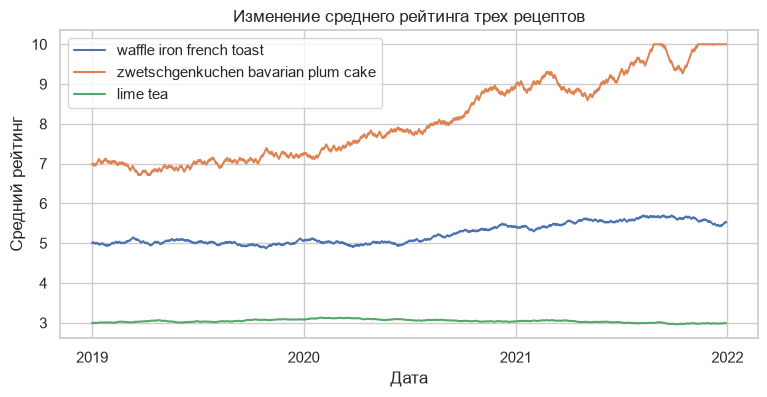

In [32]:
dates = pd.date_range("2019-01-01", "2021-12-30", freq="D")
fig, ax = plt.subplots(figsize=(9, 4))
for y, n in zip(ratings, names):
    ax.plot(dates, y, label=n)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.set(xlabel="Дата", ylabel="Средний рейтинг", title="Изменение среднего рейтинга трех рецептов")
ax.legend()

### ЛР5·3

Text(0.5, 0, 'Дата')

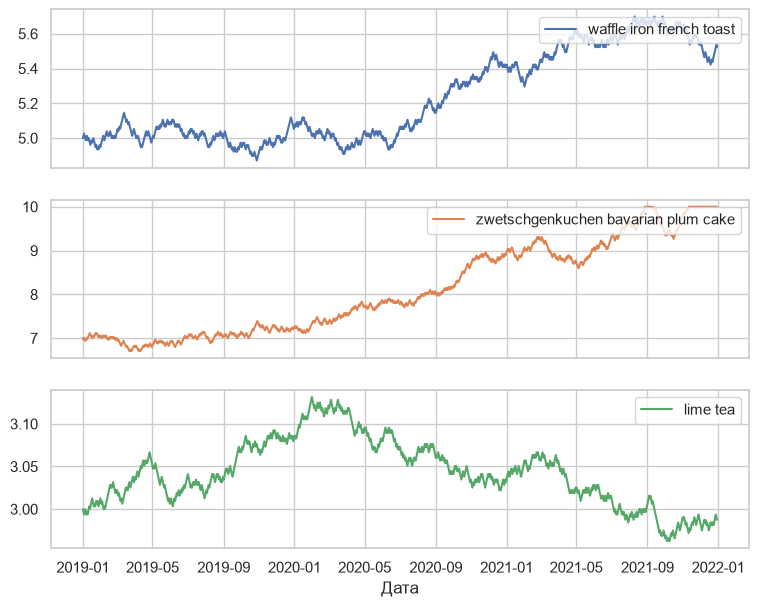

In [33]:
dates = pd.date_range("2019-01-01", "2021-12-30", freq="D")
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 7))
for i, (ax, y, n) in enumerate(zip(axes, ratings, names)):
    ax.plot(dates, y, color=f"C{i}", label=n)
    ax.legend(loc="upper right")
axes[2].set_xlabel("Дата")

### ЛР5·4

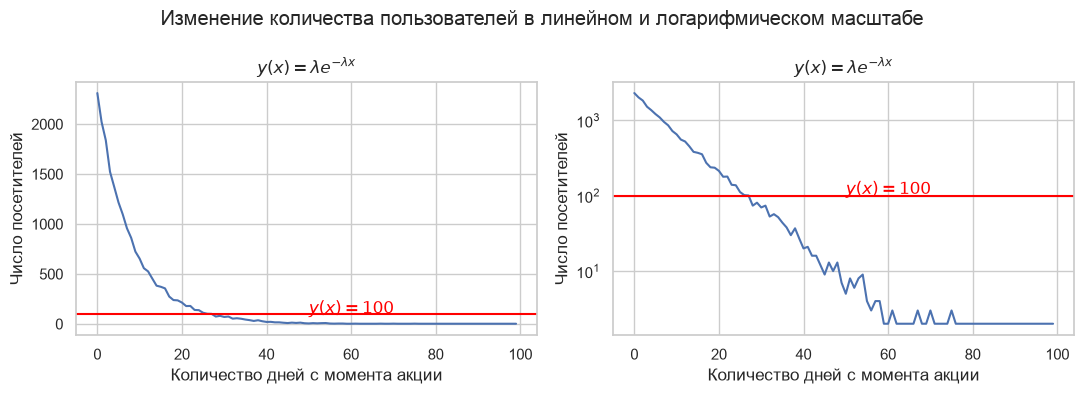

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.plot(visitors)
    ax.set_yscale(scale)
    ax.axhline(100, color="red")
    ax.text(50, 105, "$y(x)=100$", color="red")
    ax.set(title=r"$y(x)=\lambda e^{-\lambda x}$", xlabel="Количество дней с момента акции", ylabel="Число посетителей")
fig.suptitle("Изменение количества пользователей в линейном и логарифмическом масштабе")
fig.tight_layout()

### ЛР5·5

<Axes: title={'center': 'Размеры групп рецептов'}>

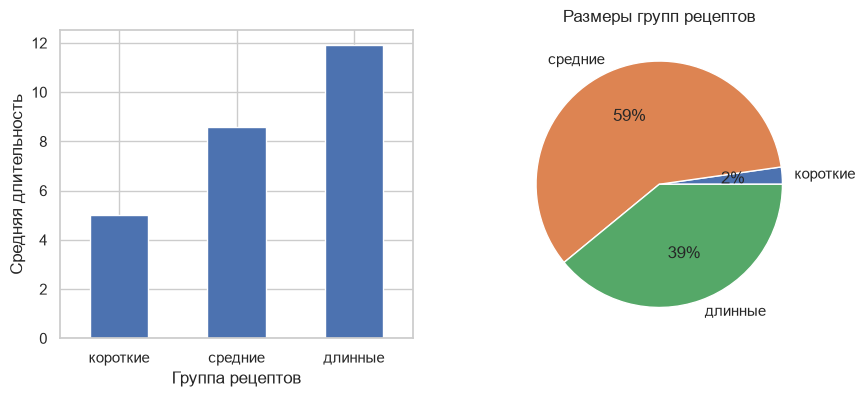

In [35]:
g = rec.groupby("kind", observed=True).agg(mean_steps=("n_steps", "mean"), size=("id", "size"))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
g["mean_steps"].plot.bar(ax=axes[0], rot=0, xlabel="Группа рецептов", ylabel="Средняя длительность")
g["size"].plot.pie(ax=axes[1], autopct="%.0f%%", title="Размеры групп рецептов", ylabel="")

### ЛР5·6

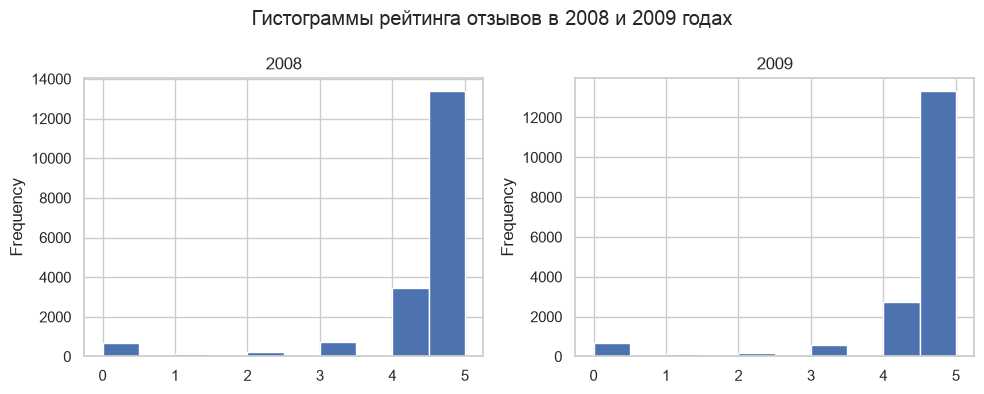

In [36]:
r08 = rev[rev["date"].dt.year == 2008]
r09 = rev[rev["date"].dt.year == 2009]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
r08["rating"].plot.hist(ax=axes[0], title="2008")
r09["rating"].plot.hist(ax=axes[1], title="2009")
fig.suptitle("Гистограммы рейтинга отзывов в 2008 и 2009 годах")
fig.tight_layout()

### ЛР5·7

Text(0.5, 1.0, 'Диаграмма рассеяния n_steps и n_ingredients')

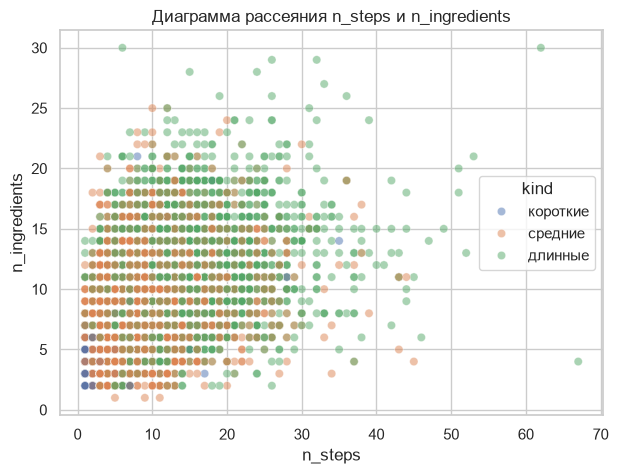

In [37]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=rec, x="n_steps", y="n_ingredients", hue="kind", alpha=0.5, ax=ax)
ax.set_title("Диаграмма рассеяния n_steps и n_ingredients")

### ЛР5·8

Text(0.5, 1.0, 'Корреляционная матрица числовых столбцов таблиц recipes и reviews')

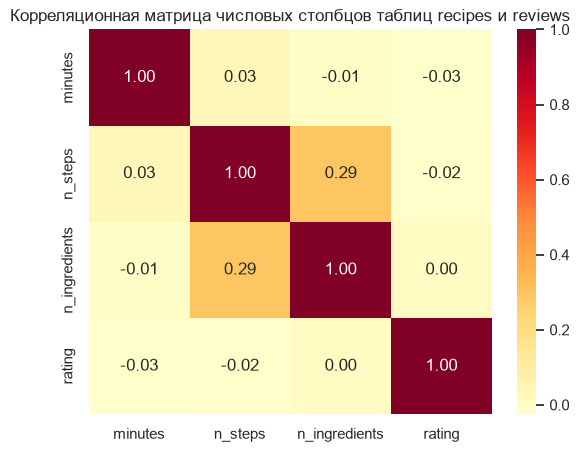

In [38]:
merged = rec.merge(rev, left_on="id", right_on="recipe_id")
corr = merged[["minutes", "n_steps", "n_ingredients", "rating"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax)
ax.set_title("Корреляционная матрица числовых столбцов таблиц recipes и reviews")

### D1

Text(0.5, 1.0, 'minutes по группам')

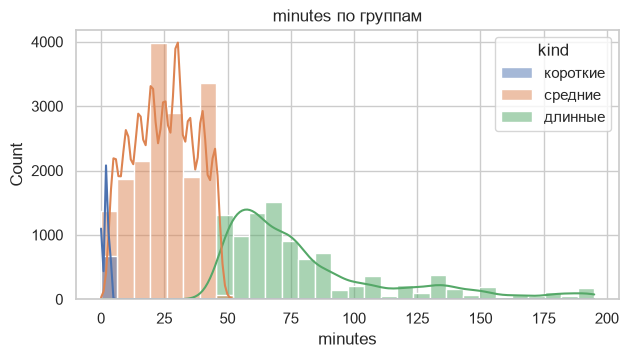

In [39]:
q = rec[rec["minutes"] < 200]
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(data=q, x="minutes", bins=30, kde=True, hue="kind", ax=ax)
ax.set_title("minutes по группам")

### D3

[Text(0.5, 1.0, 'Распределение оценок'), Text(0, 0.5, 'Отзывов')]

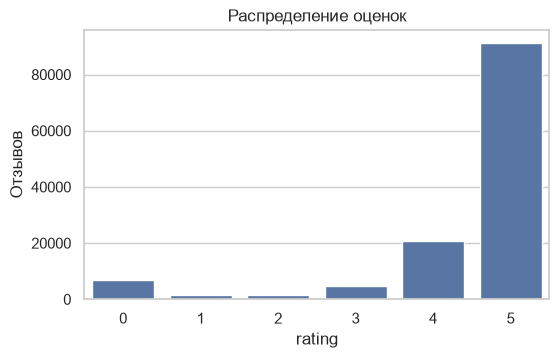

In [40]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.countplot(data=rev, x="rating", ax=ax)
ax.set(title="Распределение оценок", ylabel="Отзывов")